# F3 — Prévision de l’inflation américaine à 12 mois
**Auteur :** Toure Adja Myriam — **Code Apogée :** 20227276 — **Groupe :** G3-Fin3  
**ENCG — S7 | BD & DS | Projet de science des données appliqué à la finance**

## 1. Sujet et problématique
Les prévisions d’inflation aident les banques centrales et les acteurs financiers à apprécier l’évolution future des prix et à préparer leurs décisions. Ce projet étudie la question suivante : **le chômage et le taux des fonds fédéraux améliorent-ils la prévision de l’inflation américaine en glissement annuel à un horizon de douze mois ?** Il s’agit d’une régression supervisée sur séries temporelles mensuelles, car la cible est une valeur numérique continue. Le modèle principal est Ridge, comparé à une règle de persistance (dernière inflation disponible) et à une version Ridge utilisant seulement l’inflation passée. L’objectif retenu avant le calcul des scores de test est une réduction d’au moins 10 % du RMSE de Ridge complet par rapport à la référence naïve. Le test est chronologique et représente les 20 % les plus récents des observations exploitables.

In [1]:

import sys
import numpy
import pandas
import matplotlib
import sklearn

print("Python :", sys.version)
print("NumPy :", numpy.__version__)
print("Pandas :", pandas.__version__)
print("Matplotlib :", matplotlib.__version__)
print("Scikit-learn :", sklearn.__version__)
print("Environnement prêt !")


Python : 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
NumPy : 2.4.6
Pandas : 2.2.3
Matplotlib : 3.10.0
Scikit-learn : 1.6.1
Environnement prêt !


In [2]:
# Configuration reproductible et localisation des données du dépôt
import os
import subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

GRAINE = 42
np.random.seed(GRAINE)

fichiers = ["CPIAUCSL.csv", "UNRATE.csv", "FEDFUNDS.csv"]
def contient_donnees(dossier):
    return all((dossier / "data" / "raw" / f).is_file() for f in fichiers)

racine = next((p for p in [Path("."), Path(".."), Path("projet_F3")] if contient_donnees(p)), None)
if racine is None and "google.colab" in sys.modules:
    cible = Path("projet_F3")
    if not cible.exists():
        subprocess.run(["git", "clone", "https://github.com/Myr732/20227276-ToureAdjaMyriam-G3-Fin3.git", str(cible)], check=True)
    if contient_donnees(cible):
        racine = cible
if racine is None:
    raise FileNotFoundError("Ouvrir le notebook depuis le dépôt contenant data/raw/ et les trois CSV officiels.")
os.chdir(racine)
Path("figures").mkdir(exist_ok=True)
print("Données disponibles :", fichiers)

Données disponibles : ['CPIAUCSL.csv', 'UNRATE.csv', 'FEDFUNDS.csv']


## 2. Jeu de données
Les trois séries mensuelles des États-Unis proviennent de FRED, Federal Reserve Bank of St. Louis. Les dates d’extraction réelles sont consignées dans `docs/references.md` du dépôt. Les séries sont publiques, avec attribution demandée (mention « Public Domain: Citation Requested » sur FRED). Conditions : https://fred.stlouisfed.org/legal/terms/.

| Série | Producteur | Source | Observations brutes | Début |
|---|---|---|---:|---|
| CPIAUCSL | U.S. Bureau of Labor Statistics | [FRED](https://fred.stlouisfed.org/series/CPIAUCSL) | 958 | 1947-01 |
| UNRATE | U.S. Bureau of Labor Statistics | [FRED](https://fred.stlouisfed.org/series/UNRATE) | 946 | 1948-01 |
| FEDFUNDS | Board of Governors of the Federal Reserve System | [FRED](https://fred.stlouisfed.org/series/FEDFUNDS) | 868 | 1954-07 |

Une ligne correspond à un mois d’observation. Les données brutes ont deux colonnes chacune (date et valeur). Le jeu fusionné fournit une période commune et permet d’étudier l’information apportée par le marché du travail et la politique monétaire. Les changements de régime, valeurs manquantes et révisions des séries limitent néanmoins la portée des conclusions.

In [3]:

import pandas as pd

# Chargement des trois fichiers
cpi = pd.read_csv("data/raw/CPIAUCSL.csv")
chomage = pd.read_csv("data/raw/UNRATE.csv")
taux = pd.read_csv("data/raw/FEDFUNDS.csv")

# Affichage des premières observations
print("=== INDICE DES PRIX ===")
print(cpi.head())

print("\n=== TAUX DE CHOMAGE ===")
print(chomage.head())

print("\n=== TAUX DES FONDS FEDERAUX ===")
print(taux.head())

# Dimensions des trois jeux de données
print("\n=== DIMENSIONS ===")
print("CPI :", cpi.shape)
print("Chômage :", chomage.shape)
print("Taux directeur :", taux.shape)


=== INDICE DES PRIX ===
  observation_date  CPIAUCSL
0       1947-01-01     21.48
1       1947-02-01     21.62
2       1947-03-01     22.00
3       1947-04-01     22.00
4       1947-05-01     21.95

=== TAUX DE CHOMAGE ===
  observation_date  UNRATE
0       1948-01-01     3.4
1       1948-02-01     3.8
2       1948-03-01     4.0
3       1948-04-01     3.9
4       1948-05-01     3.5

=== TAUX DES FONDS FEDERAUX ===
  observation_date  FEDFUNDS
0       1954-07-01      0.80
1       1954-08-01      1.22
2       1954-09-01      1.07
3       1954-10-01      0.85
4       1954-11-01      0.83

=== DIMENSIONS ===
CPI : (958, 2)
Chômage : (946, 2)
Taux directeur : (868, 2)


In [4]:

# Convertir les dates au format datetime
cpi["observation_date"] = pd.to_datetime(cpi["observation_date"])
chomage["observation_date"] = pd.to_datetime(chomage["observation_date"])
taux["observation_date"] = pd.to_datetime(taux["observation_date"])

# Fusionner les trois fichiers
df = cpi.merge(chomage, on="observation_date", how="inner")
df = df.merge(taux, on="observation_date", how="inner")

# Trier les données par date
df = df.sort_values("observation_date").reset_index(drop=True)

# Afficher les résultats
print("Dimensions :", df.shape)
print("Date de début :", df["observation_date"].min())
print("Date de fin :", df["observation_date"].max())

display(df.head())


Dimensions : (868, 4)
Date de début : 1954-07-01 00:00:00
Date de fin : 2026-10-01 00:00:00


,observation_date,CPIAUCSL,UNRATE,FEDFUNDS
0,1954-07-01,26.86,5.8,0.80
1,1954-08-01,26.85,6.0,1.22
2,1954-09-01,26.81,6.1,1.07
3,1954-10-01,26.72,5.7,0.85
4,1954-11-01,26.78,5.3,0.83


Le jeu fusionné comprend 868 mois, de juillet 1954 à octobre 2026, et quatre colonnes. La fusion interne retient uniquement les dates présentes dans les trois fichiers.

### Dictionnaire des variables principales
Les taux sont exprimés en pourcentage ; les erreurs sont exprimées en points de pourcentage.

| Variable | Description / formule | Type | Unité | Rôle |
|---|---|---|---|---|
| observation_date | Mois de prévision $t$ | date | mois | Index temporel |
| CPIAUCSL | IPC américain désaisonnalisé | numérique | indice, 1982–1984 = 100 | Source de la cible |
| UNRATE | Taux de chômage désaisonnalisé | numérique | % | Source explicative |
| FEDFUNDS | Taux effectif des fonds fédéraux, moyenne mensuelle | numérique | % | Source explicative |
| Inflation | $100(IPC_t/IPC_{t-12}-1)$ | numérique | % | Série à prévoir |
| Inflation_lag1 / lag3 | Inflation aux mois $t-1$ et $t-3$ | numérique | % | Explicatives |
| Chomage_lag1 | UNRATE au mois $t-1$ | numérique | % | Explicative |
| Taux_lag1 | FEDFUNDS au mois $t-1$ | numérique | % | Explicative |
| Cible / Date_cible | Inflation au mois $t+12$ et sa date | numérique / date | % / mois | Cible / date cible |

Les taux de valeurs manquantes des séries brutes fusionnées et des variables dérivées sont vérifiés dans les sections suivantes.

## 3. Exploration
### Qualité et statistiques descriptives

In [5]:

# Types des variables
print("=== TYPES DES VARIABLES ===")
print(df.dtypes)

# Valeurs manquantes
print("\n=== VALEURS MANQUANTES ===")
print(df.isna().sum())

# Pourcentage des valeurs manquantes
print("\n=== POURCENTAGE DES VALEURS MANQUANTES ===")
print(df.isna().mean() * 100)

# Doublons
print("\n=== DOUBLONS ===")
print(df.duplicated().sum())

# Vérification des dates mensuelles
dates_attendues = pd.date_range(
    df["observation_date"].min(),
    df["observation_date"].max(),
    freq="MS"
)

print("\n=== MOIS MANQUANTS ===")
print(dates_attendues.difference(df["observation_date"]))

# Statistiques descriptives
print("\n=== STATISTIQUES DESCRIPTIVES ===")
display(df.describe())


=== TYPES DES VARIABLES ===
observation_date    datetime64[ns]
CPIAUCSL                   float64
UNRATE                     float64
FEDFUNDS                   float64
dtype: object

=== VALEURS MANQUANTES ===
observation_date    0
CPIAUCSL            1
UNRATE              1
FEDFUNDS            0
dtype: int64

=== POURCENTAGE DES VALEURS MANQUANTES ===
observation_date    0.000000
CPIAUCSL            0.115207
UNRATE              0.115207
FEDFUNDS            0.000000
dtype: float64

=== DOUBLONS ===
0

=== MOIS MANQUANTS ===
DatetimeIndex([], dtype='datetime64[ns]', freq='MS')

=== STATISTIQUES DESCRIPTIVES ===


,observation_date,CPIAUCSL,UNRATE,FEDFUNDS
count,868,867.000000,867.000000,868.000000
mean,1990-08-16 10:58:37.050691200,136.521348,5.785928,4.593053
min,1954-07-01 00:00:00,26.710000,3.400000,0.050000
25%,1972-07-24 06:00:00,41.850000,4.400000,1.945000
50%,1990-08-16 12:00:00,131.600000,5.500000,4.245000
75%,2008-09-08 12:00:00,213.087500,6.850000,6.105000
max,2026-10-01 00:00:00,337.476000,14.800000,19.100000
std,NaN,89.548337,1.668222,3.523839


### Description et qualité du jeu de données

Après fusion des trois séries économiques sur la base de la date d'observation, le jeu de données comporte 868 observations mensuelles et quatre variables. La période étudiée s'étend de juillet 1954 à octobre 2026.

L'analyse de la qualité des données révèle l'absence de doublons et de mois manquants. Toutefois, les variables CPIAUCSL et UNRATE présentent chacune une valeur manquante, représentant environ 0,115 % des observations.

Le taux de chômage moyen s'établit à 5,79 %, tandis que le taux moyen des fonds fédéraux atteint 4,59 %. La dispersion des taux d'intérêt est plus importante que celle du chômage sur la période étudiée.

La vérification confirme l’absence de mois manquants. Les deux valeurs manquantes (IPC et chômage) sont observées en octobre 2025. On conserve la grille mensuelle et les valeurs extrêmes : une hausse ou baisse exceptionnelle peut être économiquement réelle. Les lignes non exploitables seront éliminées après construction des retards et de la cible, sans interpolation vers le futur.

In [6]:

# Identifier les observations incomplètes
print("Observations incomplètes :")
display(df[df.isna().any(axis=1)])

# Calculer l'inflation sur la série CPI complète
ipc = cpi.set_index("observation_date")["CPIAUCSL"]
ipc = ipc.sort_index().asfreq("MS")

inflation = ipc.pct_change(
    periods=12, fill_method=None
) * 100

# Ajouter l'inflation au tableau principal
df["Inflation"] = df["observation_date"].map(inflation)

# Vérifier le résultat
display(df.head(15))

print("Valeurs manquantes :")
print(df.isna().sum())

print("Statistiques de l'inflation :")
print(df["Inflation"].describe())


Observations incomplètes :


,observation_date,CPIAUCSL,UNRATE,FEDFUNDS
855,2025-10-01,NaN,NaN,4.09


,observation_date,CPIAUCSL,UNRATE,FEDFUNDS,Inflation
0,1954-07-01,26.86,5.8,0.80,0.261292
1,1954-08-01,26.85,6.0,1.22,0.000000
2,1954-09-01,26.81,6.1,1.07,-0.297508
3,1954-10-01,26.72,5.7,0.85,-0.853432
4,1954-11-01,26.78,5.3,0.83,-0.260708
5,1954-12-01,26.77,5.0,1.28,-0.372162
6,1955-01-01,26.77,4.9,1.39,-0.631032
7,1955-02-01,26.82,4.7,1.29,-0.629863
8,1955-03-01,26.79,4.6,1.35,-0.519866
9,1955-04-01,26.79,4.7,1.43,-0.260611


Valeurs manquantes :
observation_date    0
CPIAUCSL            1
UNRATE              1
FEDFUNDS            0
Inflation           2
dtype: int64
Statistiques de l'inflation :
count    866.000000
mean       3.568194
std        2.763883
min       -1.958761
25%        1.728850
50%        2.939084
75%        4.369589
max       14.592275
Name: Inflation, dtype: float64


L’inflation annuelle est calculée sur l’historique complet de l’IPC, avant rattachement à la période commune. Les deux valeurs manquantes d’inflation découlent de l’IPC manquant et de la comparaison douze mois plus tard. Sur 866 observations disponibles, la moyenne est de 3,568 %, l’écart-type de 2,764 points et les extrêmes de −1,959 % et 14,592 %.

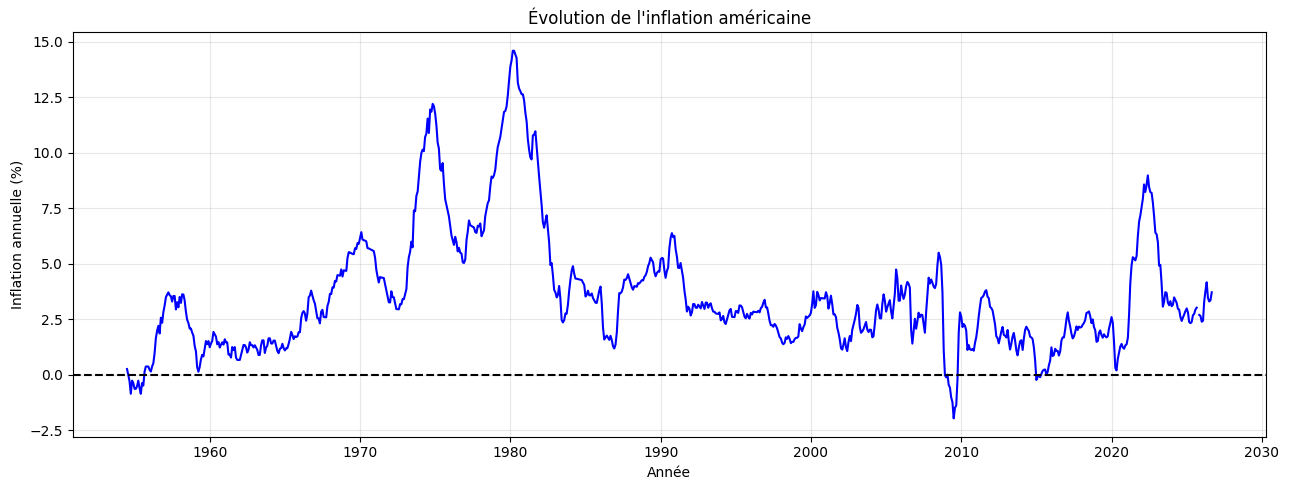

In [7]:

import matplotlib.pyplot as plt
from pathlib import Path

Path("figures").mkdir(exist_ok=True)

plt.figure(figsize=(13, 5))

plt.plot(df["observation_date"],
         df["Inflation"], color="blue")

plt.axhline(0, color="black", linestyle="--")

plt.title("Évolution de l'inflation américaine")
plt.xlabel("Année")
plt.ylabel("Inflation annuelle (%)")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("figures/01_inflation.png", dpi=300)
plt.show()


Graphique 1 — Évolution historique de l'inflation

L'évolution de l'inflation américaine présente d'importantes fluctuations entre 1954 et 2026. Les niveaux les plus élevés sont observés durant les années 1970 et au début des années 1980, avec un pic proche de 15 %. Une période de déflation apparaît en 2009, tandis qu'une forte reprise inflationniste est observée autour de 2022. Ces variations témoignent de changements de régime économique susceptibles de compliquer les prévisions.

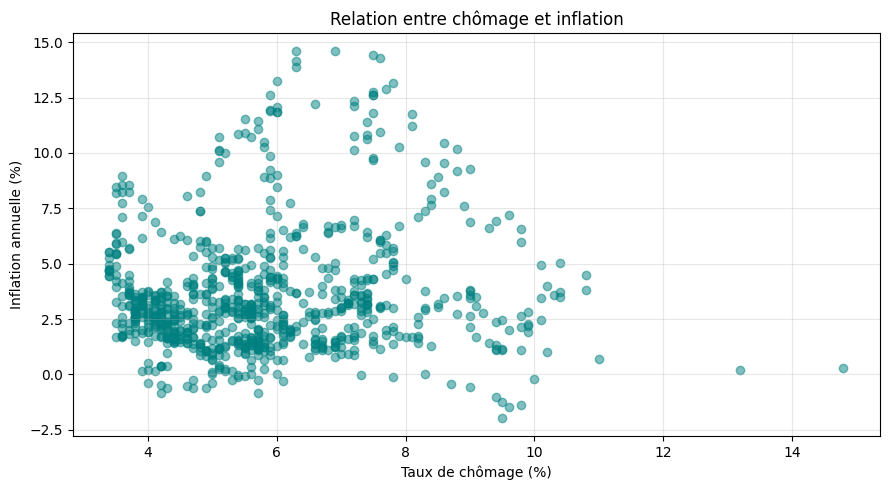

In [8]:

plt.figure(figsize=(9, 5))

plt.scatter(df["UNRATE"],
            df["Inflation"],
            color="teal", alpha=0.5)

plt.title("Relation entre chômage et inflation")
plt.xlabel("Taux de chômage (%)")
plt.ylabel("Inflation annuelle (%)")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("figures/02_chomage_inflation.png", dpi=300)
plt.show()


Graphique 2 — Relation entre chômage et inflation

Le nuage de points présente une forte dispersion, sans relation linéaire clairement identifiable entre le chômage et l'inflation. Le coefficient de corrélation de 0,096 confirme la faiblesse de cette relation contemporaine. Toutefois, le chômage pourrait présenter un pouvoir prédictif lorsqu'il est utilisé avec des retards temporels.

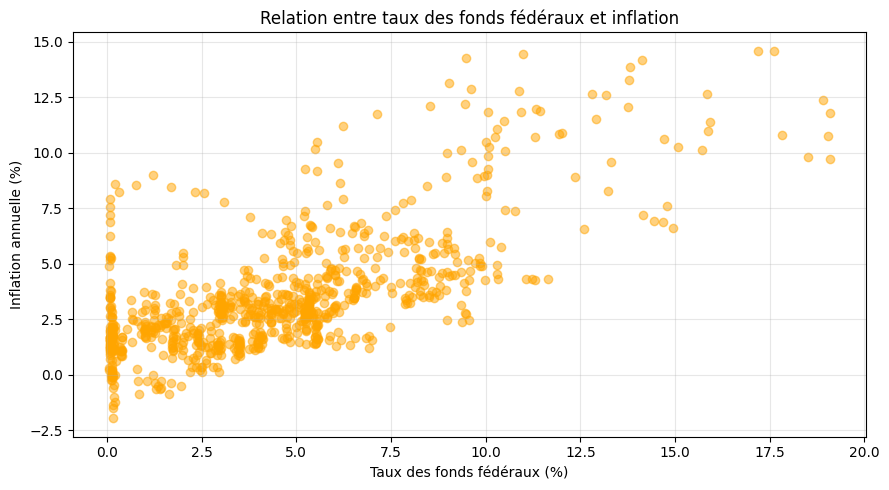

In [9]:

plt.figure(figsize=(9, 5))

plt.scatter(df["FEDFUNDS"],
            df["Inflation"],
            color="orange", alpha=0.5)

plt.title("Relation entre taux des fonds fédéraux et inflation")
plt.xlabel("Taux des fonds fédéraux (%)")
plt.ylabel("Inflation annuelle (%)")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("figures/03_taux_inflation.png", dpi=300)
plt.show()


Graphique 3 — Relation entre taux des fonds fédéraux et inflation

Le graphique révèle une relation positive entre le taux des fonds fédéraux et l'inflation. Le coefficient de corrélation de 0,708 indique une association linéaire relativement forte. Cette relation pourrait notamment s'expliquer par les réactions de la Réserve fédérale face aux pressions inflationnistes. Cependant, cette corrélation ne permet pas d'établir une relation de causalité.

In [10]:

correlations = df[
    ["Inflation", "UNRATE", "FEDFUNDS"]
].corr()

display(correlations.round(3))


,Inflation,UNRATE,FEDFUNDS
Inflation,1.000,0.096,0.708
UNRATE,0.096,1.000,0.067
FEDFUNDS,0.708,0.067,1.000


### Analyse des corrélations

La matrice de corrélation révèle une faible relation linéaire entre le taux de chômage et l'inflation (0,096), contrairement au taux des fonds fédéraux qui présente une corrélation positive relativement forte avec l'inflation (0,708).

La corrélation entre les deux variables explicatives reste faible (0,067). Ces premiers résultats justifient l'étude de leur contribution à la prévision de l'inflation. Toutefois, les corrélations contemporaines ne permettent pas de conclure directement à leur capacité prédictive à un horizon de douze mois.

L’exploration ci-dessus est descriptive et porte sur l’ensemble de la série. Elle ne constitue pas une évaluation hors échantillon. Dans un protocole plus strict, les choix exploratoires de modélisation seraient effectués exclusivement sur l’apprentissage.

## 4. Préparation
On conserve la fréquence mensuelle et on construit les retards avant d’écarter les observations incomplètes. Les variables de mois $t-1$ et $t-3$ sont utilisées pour réduire le risque de disponibilité tardive des publications. La cible est l’inflation en glissement annuel du mois $t+12$. Les retards et la cible sont calculés sur la grille complète, afin qu’une ligne supprimée ne transforme pas un mois de retard en deux mois. La standardisation est intégrée à un Pipeline ajusté sur les seules données d’apprentissage de chaque pli.

In [11]:
# Contrôle du calendrier avant les décalages
assert df["observation_date"].is_unique
assert df["observation_date"].is_monotonic_increasing
assert pd.DatetimeIndex(df["observation_date"]).equals(pd.date_range(df["observation_date"].min(), df["observation_date"].max(), freq="MS"))
print("Calendrier mensuel complet et sans doublon de date.")

Calendrier mensuel complet et sans doublon de date.


In [12]:

# Copier et trier les données
data = df.copy()
data = data.sort_values("observation_date")

# Créer les variables retardées
data["Inflation_lag1"] = data["Inflation"].shift(1)
data["Inflation_lag3"] = data["Inflation"].shift(3)
data["Chomage_lag1"] = data["UNRATE"].shift(1)
data["Taux_lag1"] = data["FEDFUNDS"].shift(1)

# Créer la cible à 12 mois
data["Cible"] = data["Inflation"].shift(-12)

data["Date_cible"] = (
    data["observation_date"] + pd.DateOffset(months=12)
)

# Sélectionner les variables explicatives
variables = [
    "Inflation_lag1",
    "Inflation_lag3",
    "Chomage_lag1",
    "Taux_lag1"
]

# Supprimer les lignes incomplètes après les décalages
data = data.dropna(subset=variables + ["Cible"])
data = data.reset_index(drop=True)

print("Dimensions après préparation :", data.shape)

display(data[
    ["observation_date"] + variables
    + ["Date_cible", "Cible"]
].head())


Dimensions après préparation : (851, 11)


,observation_date,Inflation_lag1,Inflation_lag3,Chomage_lag1,Taux_lag1,Date_cible,Cible
0,1954-10-01,-0.297508,0.261292,6.1,1.07,1955-10-01,0.374251
1,1954-11-01,-0.853432,0.000000,5.7,0.85,1955-11-01,0.373413
2,1954-12-01,-0.260708,-0.297508,5.3,0.83,1955-12-01,0.373552
3,1955-01-01,-0.372162,-0.853432,5.0,1.28,1956-01-01,0.224131
4,1955-02-01,-0.631032,-0.260708,4.9,1.39,1956-02-01,0.149142


Les premières lignes confirment que chaque date cible est douze mois après la date de prévision. Après suppression des lignes incomplètes sur les quatre prédicteurs et la cible, il reste 851 observations. Les variables explicatives et la cible ne contiennent plus de valeurs manquantes.

## 5. Algorithme
La régression Ridge (algorithme n° 2 du support) est une régression linéaire multiple avec régularisation L2. Pour des prédicteurs standardisés, elle recherche des coefficients qui minimisent la somme des erreurs quadratiques augmentée d’une pénalité :

$$\mathcal L(\beta_0,\beta)=\sum_{i=1}^{n}(y_i-\beta_0-\sum_{j=1}^{p}\beta_j z_{ij})^2+\alpha\sum_{j=1}^{p}\beta_j^2.$$

$y_i$ est l’inflation cible, $z_{ij}$ la variable explicative standardisée, $n$ le nombre d’observations, $p$ le nombre de variables, $\beta_0$ l’interception, $\beta_j$ les coefficients appris et $\alpha$ la force de pénalisation. Une valeur faible de $\alpha$ rapproche Ridge des moindres carrés ; une valeur élevée réduit fortement les coefficients et peut conduire au sous-ajustement. Le paramètre `fit_intercept=True` conserve une constante (non pénalisée). Le solveur `auto` est laissé par défaut. Seul alpha est réglé. Ridge est rapide, interprétable et limite l’instabilité des coefficients lorsque les retards d’inflation sont corrélés. Le gradient boosting est une alternative non linéaire, mais plus complexe à régler et moins directement interprétable par ses coefficients.

## 6. Protocole expérimental
Le découpage est chronologique, avec environ 80 % des données avant la séparation et 20 % pour le test. Un écart de 13 observations est exclu avant le test, compte tenu de l’horizon de 12 mois et d’une marge liée à la publication des données. Les cinq plis de TimeSeriesSplit respectent le même écart. Les cinq configurations d’alpha sont choisies sur l’apprentissage uniquement (cinq pour Ridge complet et cinq pour Ridge réduit). La référence naïve correspond à l’inflation du mois $t-1$, dernière valeur supposée disponible à la date de prévision. Ridge réduit permet de mesurer l’apport supplémentaire du chômage et du taux d’intérêt sur les mêmes dates et avec le même protocole.

- **RMSE**, métrique principale : $\sqrt{\frac{1}{n}\sum_i(y_i-\hat y_i)^2}$, en points de pourcentage ; pénalise fortement les grandes erreurs.
- **MAE**, métrique secondaire : moyenne des erreurs absolues, en points de pourcentage, plus directement interprétable.
- **R²**, métrique secondaire : mesure de l’ajustement relatif à la moyenne des valeurs réelles ; sans unité, il peut être négatif hors échantillon.

Aucun réglage ne doit être effectué à partir du score de test.

In [13]:

# Définir le point de séparation
separation = int(len(data) * 0.8)
gap = 13

# Découpage chronologique
train = data.iloc[:separation-gap].copy()
test = data.iloc[separation:].copy()

X_train = train[variables]
y_train = train["Cible"]

X_test = test[variables]
y_test = test["Cible"]

print("Observations apprentissage :", len(train))
print("Observations test :", len(test))

print("\nPériode apprentissage :")
print(train["observation_date"].min(),
      train["observation_date"].max())

print("\nPériode test :")
print(test["observation_date"].min(),
      test["observation_date"].max())

print("\nDernière cible d'apprentissage :")
print(train["Date_cible"].max())


Observations apprentissage : 667
Observations test : 171

Période apprentissage :
1954-10-01 00:00:00 2010-04-01 00:00:00

Période test :
2011-06-01 00:00:00 2025-09-01 00:00:00

Dernière cible d'apprentissage :
2011-04-01 00:00:00


L’apprentissage contient 667 observations (dates de prévision d’octobre 1954 à avril 2010) et le test 171 (juin 2011 à septembre 2025). Treize observations sont écartées entre les deux. La dernière date cible d’apprentissage est avril 2011 ; les dates cibles du test vont de juin 2012 à septembre 2026.

In [14]:

from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit
from sklearn.model_selection import GridSearchCV

# Pipeline : standardisation puis régression Ridge
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge())
])

# Hyperparamètre à optimiser
parametres = {
    "ridge__alpha": [0.1, 1, 10, 100, 1000]
}

# Validation croisée chronologique
cv = TimeSeriesSplit(n_splits=5, gap=13)

# Recherche de la meilleure configuration
recherche = GridSearchCV(
    pipeline,
    parametres,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    return_train_score=True
)

# Entraînement
recherche.fit(X_train, y_train)

modele_final = recherche.best_estimator_

print("Meilleur alpha :", recherche.best_params_)
print("RMSE moyen en validation :", -recherche.best_score_)

# Résultats de validation
resultats_cv = pd.DataFrame(recherche.cv_results_)

display(resultats_cv[
    ["param_ridge__alpha",
     "mean_train_score",
     "mean_test_score",
     "std_test_score"]
])


Meilleur alpha : {'ridge__alpha': 10}
RMSE moyen en validation : 2.471052075147635


,param_ridge__alpha,mean_train_score,mean_test_score,std_test_score
0,0.1,-1.408616,-2.574531,1.268315
1,1.0,-1.411755,-2.539898,1.271926
2,10.0,-1.444446,-2.471052,1.242218
3,100.0,-1.518148,-2.484748,1.180219
4,1000.0,-1.877764,-2.770023,1.490321


### Préparation des données et optimisation du modèle

Après la création des variables retardées et de la cible à douze mois, le jeu de données comporte 851 observations exploitables. Le découpage chronologique permet de retenir 667 observations pour l'apprentissage et 171 pour le test, avec un écart de sécurité de 13 observations afin de limiter les fuites temporelles.

La recherche des hyperparamètres a été effectuée à l'aide de GridSearchCV et d'une validation croisée chronologique à cinq plis. Parmi les cinq valeurs d'alpha testées, la valeur 10 présente les meilleures performances, avec un RMSE moyen en validation de 2,471 points de pourcentage et un écart-type de 1,242.

Le modèle retenu présente néanmoins un écart entre ses performances en apprentissage et en validation, ce qui justifie une analyse de sa capacité de généralisation sur le jeu de test.

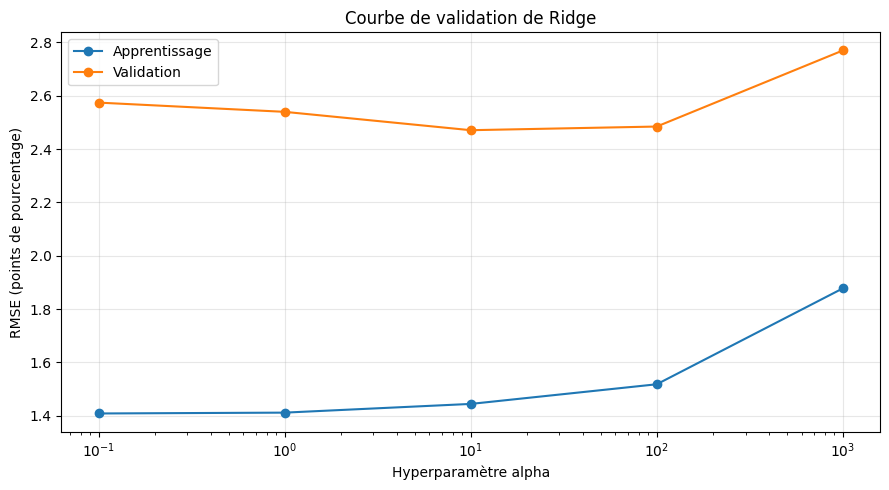

In [15]:

plt.figure(figsize=(9, 5))

plt.semilogx(
    resultats_cv["param_ridge__alpha"].astype(float),
    -resultats_cv["mean_train_score"],
    marker="o",
    label="Apprentissage"
)

plt.semilogx(
    resultats_cv["param_ridge__alpha"].astype(float),
    -resultats_cv["mean_test_score"],
    marker="o",
    label="Validation"
)

plt.title("Courbe de validation de Ridge")
plt.xlabel("Hyperparamètre alpha")
plt.ylabel("RMSE (points de pourcentage)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("figures/07_validation.png", dpi=300)
plt.show()


La courbe de validation montre que la valeur optimale de l'hyperparamètre alpha est égale à 10, avec un RMSE moyen en validation de 2,471. Une régularisation excessive, notamment pour alpha égal à 1 000, entraîne une dégradation des performances. L'écart persistant entre les erreurs d'apprentissage et de validation suggère des difficultés de généralisation, potentiellement liées aux changements de régime économique et au surapprentissage.

## 7. Résultats
### Comparaison des trois méthodes

In [16]:

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# Fonction de calcul du RMSE
def calcul_rmse(reel, predit):
    return np.sqrt(mean_squared_error(reel, predit))

# Modèle Ridge utilisant uniquement l'inflation passée
variables_reduites = [
    "Inflation_lag1",
    "Inflation_lag3"
]

recherche_reduite = GridSearchCV(
    pipeline,
    parametres,
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

recherche_reduite.fit(
    X_train[variables_reduites], y_train
)

# Validation de la méthode naïve
scores_naifs = []

for _, indice_val in cv.split(X_train):
    score = calcul_rmse(
        y_train.iloc[indice_val],
        X_train.iloc[indice_val]["Inflation_lag1"]
    )
    scores_naifs.append(score)

# Prédictions finales sur le test
predictions = modele_final.predict(X_test)

predictions_reduites = recherche_reduite.predict(
    X_test[variables_reduites]
)

predictions_naives = X_test["Inflation_lag1"]

# Tableau comparatif
resultats = pd.DataFrame({
    "Modèle": [
        "Méthode naïve",
        "Ridge réduit",
        "Ridge complet"
    ],
    "RMSE validation": [
        np.mean(scores_naifs),
        -recherche_reduite.best_score_,
        -recherche.best_score_
    ],
    "RMSE test": [
        calcul_rmse(y_test, predictions_naives),
        calcul_rmse(y_test, predictions_reduites),
        calcul_rmse(y_test, predictions)
    ],
    "MAE test": [
        mean_absolute_error(y_test, predictions_naives),
        mean_absolute_error(y_test, predictions_reduites),
        mean_absolute_error(y_test, predictions)
    ],
    "R2 test": [
        r2_score(y_test, predictions_naives),
        r2_score(y_test, predictions_reduites),
        r2_score(y_test, predictions)
    ]
})

display(resultats.round(3))

# Amélioration par rapport à la méthode naïve
rmse_naif = calcul_rmse(y_test, predictions_naives)
rmse_ridge = calcul_rmse(y_test, predictions)

gain = (1 - rmse_ridge / rmse_naif) * 100

print("Amélioration :", round(gain, 2), "%")
print("Objectif de 10 % atteint :", gain >= 10)
print("Meilleur alpha Ridge réduit :",
      recherche_reduite.best_params_)


,Modèle,RMSE validation,RMSE test,MAE test,R2 test
0,Méthode naïve,2.033,2.178,1.534,-0.206
1,Ridge réduit,2.274,1.956,1.443,0.027
2,Ridge complet,2.471,2.118,1.489,-0.141


Amélioration : 2.73 %
Objectif de 10 % atteint : False
Meilleur alpha Ridge réduit : {'ridge__alpha': 10}


In [17]:

display(resultats.round(4))

print("Amélioration de Ridge :", round(gain, 2), "%")

print("Objectif de 10 % atteint :", gain >= 10)


,Modèle,RMSE validation,RMSE test,MAE test,R2 test
0,Méthode naïve,2.0328,2.1777,1.5336,-0.2060
1,Ridge réduit,2.2740,1.9556,1.4431,0.0275
2,Ridge complet,2.4711,2.1182,1.4892,-0.1410


Amélioration de Ridge : 2.73 %
Objectif de 10 % atteint : False


### Comparaison des performances des modèles

Les résultats montrent que le modèle Ridge réduit obtient les meilleures performances sur le jeu de test, avec un RMSE de 1,9556, contre 2,1182 pour Ridge complet et 2,1777 pour la méthode naïve.

Le modèle Ridge complet améliore les performances de la référence naïve de 2,73 %. Toutefois, cette amélioration reste inférieure à l'objectif initial de 10 %. Le modèle Ridge réduit présente une amélioration d'environ 10,20 % par rapport à la référence.

L'intégration du taux de chômage et du taux des fonds fédéraux ne permet donc pas d'améliorer les performances prédictives par rapport au modèle utilisant uniquement l'inflation passée. Par ailleurs, la méthode naïve obtient le meilleur RMSE en validation, ce qui souligne la variabilité des performances selon les périodes étudiées.

Le coefficient de détermination négatif de Ridge complet indique que ses performances sur le test sont inférieures à celles d'une référence constante égale à la moyenne des valeurs réelles du test.

In [18]:
# Complément : dispersion du RMSE et métriques secondaires en validation
from sklearn.base import clone
from sklearn.model_selection import cross_validate

scoring = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}
comparatif_cv = []
mae_naif, r2_naif = [], []
for _, idx in cv.split(X_train):
    vrai = y_train.iloc[idx]
    prev = X_train.iloc[idx]["Inflation_lag1"]
    mae_naif.append(mean_absolute_error(vrai, prev))
    r2_naif.append(r2_score(vrai, prev))
comparatif_cv.append(["Méthode naïve", np.mean(scores_naifs), np.std(scores_naifs), np.mean(mae_naif), np.mean(r2_naif)])
for nom, estimateur, cols in [("Ridge réduit", recherche_reduite.best_estimator_, variables_reduites), ("Ridge complet", modele_final, variables)]:
    sc = cross_validate(clone(estimateur), X_train[cols], y_train, cv=cv, scoring=scoring)
    comparatif_cv.append([nom, -sc["test_rmse"].mean(), sc["test_rmse"].std(), -sc["test_mae"].mean(), sc["test_r2"].mean()])

display(pd.DataFrame(comparatif_cv, columns=["Modèle", "RMSE validation", "Écart-type RMSE", "MAE validation", "R² validation"]).round(4))

,Modèle,RMSE validation,Écart-type RMSE,MAE validation,R² validation
0,Méthode naïve,2.0328,0.8718,1.6467,-0.7410
1,Ridge réduit,2.2740,0.9323,1.8029,-1.1821
2,Ridge complet,2.4711,1.2422,1.9634,-1.4819


Le tableau complémentaire présente les scores moyens et la dispersion sur les cinq plis pour les configurations déjà retenues ; il ne sert pas à modifier le réglage après consultation du test.

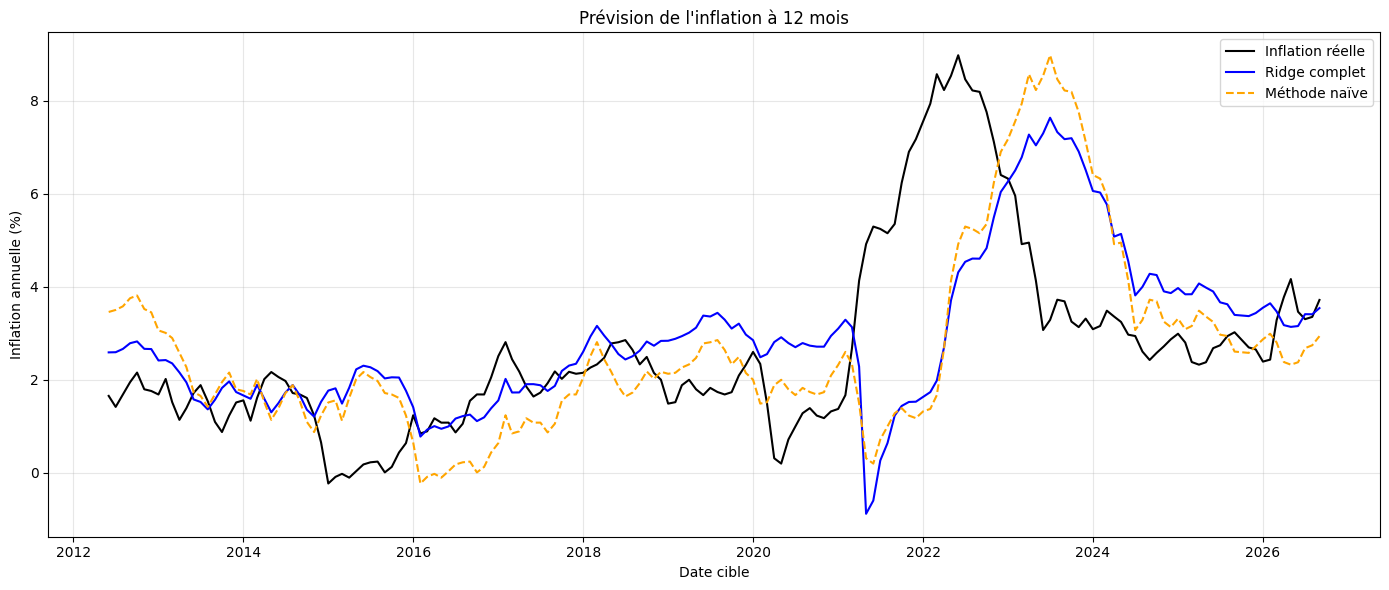

In [19]:

plt.figure(figsize=(14, 6))

plt.plot(
    test["Date_cible"], y_test,
    label="Inflation réelle", color="black"
)

plt.plot(
    test["Date_cible"], predictions,
    label="Ridge complet", color="blue"
)

plt.plot(
    test["Date_cible"], predictions_naives,
    label="Méthode naïve",
    color="orange", linestyle="--"
)

plt.title("Prévision de l'inflation à 12 mois")
plt.xlabel("Date cible")
plt.ylabel("Inflation annuelle (%)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "figures/04_previsions.png", dpi=300
)

plt.show()


Le modèle Ridge parvient à reproduire certaines tendances générales de l'inflation américaine. Toutefois, il présente des difficultés à anticiper les fortes variations observées entre 2021 et 2023. Il sous-estime notamment la hausse inflationniste de 2021-2022, puis surestime l'inflation lors de son ralentissement en 2023. Ces résultats illustrent les limites du modèle face aux changements de régime économique.

,Variable,Coefficient,Importance_absolue
0,Inflation_lag1,2.0204,2.0204
2,Chomage_lag1,-0.3344,0.3344
3,Taux_lag1,0.2156,0.2156
1,Inflation_lag3,-0.0286,0.0286


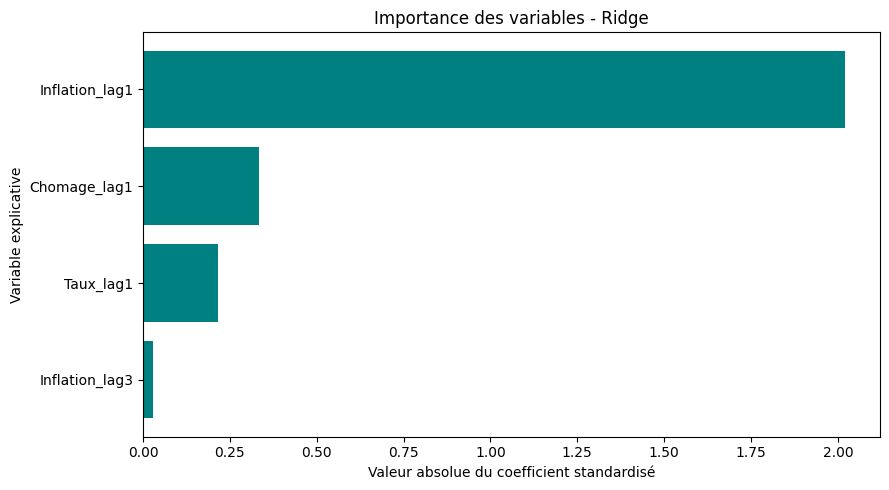

In [20]:

# Récupérer les coefficients du modèle
coefficients = pd.DataFrame({
    "Variable": variables,
    "Coefficient": modele_final.named_steps["ridge"].coef_
})

coefficients["Importance_absolue"] = (
    coefficients["Coefficient"].abs()
)

coefficients = coefficients.sort_values(
    "Importance_absolue", ascending=False
)

display(coefficients.round(4))

# Représentation graphique
plt.figure(figsize=(9, 5))

plt.barh(
    coefficients["Variable"],
    coefficients["Importance_absolue"],
    color="teal"
)

plt.gca().invert_yaxis()

plt.title("Importance des variables - Ridge")
plt.xlabel("Valeur absolue du coefficient standardisé")
plt.ylabel("Variable explicative")
plt.tight_layout()

plt.savefig(
    "figures/05_importance_variables.png",
    dpi=300
)

plt.show()


L'analyse des coefficients standardisés montre que l'inflation retardée d'un mois constitue la variable dominante du modèle Ridge, avec un coefficient de 2,0204. Le chômage et le taux des fonds fédéraux présentent des coefficients respectifs de -0,3344 et 0,2156. Leur contribution apparaît moins importante que celle de l'inflation passée. Ces coefficients décrivent les relations apprises par le modèle et ne permettent pas d'établir une relation de causalité.

Cinq prévisions les moins précises :


,Date,Inflation_reelle,Prediction_Ridge,Prediction_naive,Erreur,Erreur_absolue
117,2022-03-01,8.572,1.983,1.670,6.589,6.589
116,2022-02-01,7.937,1.735,1.374,6.202,6.202
115,2022-01-01,7.559,1.631,1.320,5.928,5.928
108,2021-06-01,5.296,-0.597,0.198,5.893,5.893
107,2021-05-01,4.918,-0.881,0.313,5.800,5.800


Exemples de prévisions :


,Date,Inflation_reelle,Prediction_Ridge,Prediction_naive,Erreur,Erreur_absolue
0,2012-06-01,1.654,2.590,3.459,-0.936,0.936
1,2012-07-01,1.418,2.593,3.502,-1.176,1.176
2,2012-08-01,1.686,2.664,3.580,-0.978,0.978
3,2012-09-01,1.950,2.787,3.755,-0.837,0.837
4,2012-10-01,2.156,2.825,3.813,-0.669,0.669


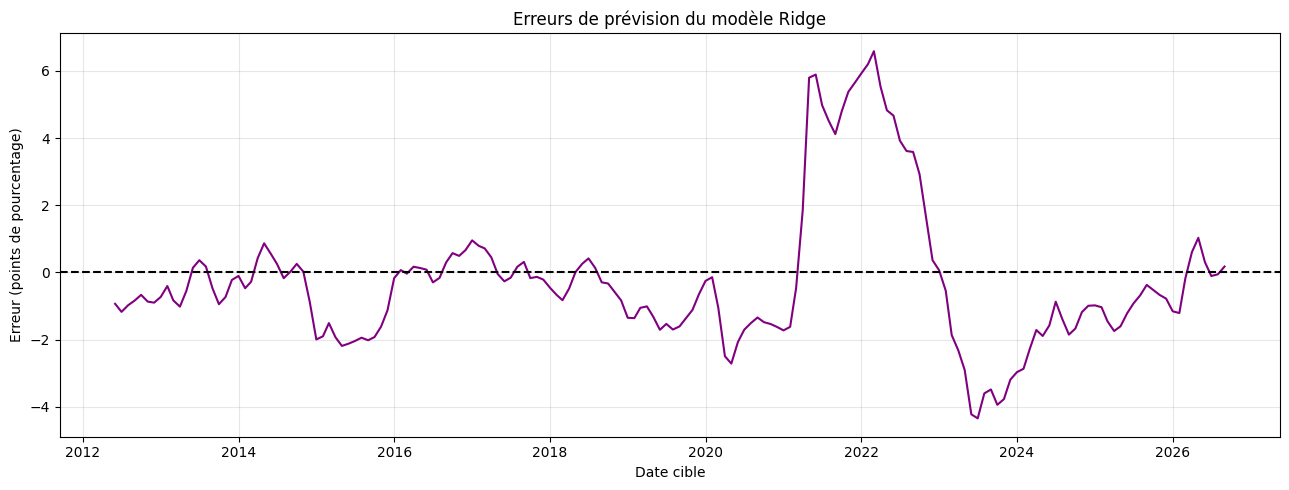

2012-06-01 00:00:00 2019-06-01 00:00:00 RMSE : 0.927
2019-07-01 00:00:00 2026-09-01 00:00:00 RMSE : 2.841


In [21]:

# Construire le tableau des prédictions
analyse = pd.DataFrame({
    "Date": test["Date_cible"].values,
    "Inflation_reelle": y_test.values,
    "Prediction_Ridge": predictions,
    "Prediction_naive": predictions_naives.values
})

# Calculer les erreurs
analyse["Erreur"] = (
    analyse["Inflation_reelle"]
    - analyse["Prediction_Ridge"]
)

analyse["Erreur_absolue"] = analyse["Erreur"].abs()

print("Cinq prévisions les moins précises :")

display(
    analyse.nlargest(5, "Erreur_absolue").round(3)
)

print("Exemples de prévisions :")
display(analyse.head(5).round(3))

# Graphique des erreurs
plt.figure(figsize=(13, 5))

plt.plot(
    analyse["Date"],
    analyse["Erreur"],
    color="purple"
)

plt.axhline(0, color="black", linestyle="--")

plt.title("Erreurs de prévision du modèle Ridge")
plt.xlabel("Date cible")
plt.ylabel("Erreur (points de pourcentage)")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("figures/06_erreurs.png", dpi=300)
plt.show()

# Stabilité sur deux sous-périodes
milieu = len(analyse) // 2

for periode in [
    analyse.iloc[:milieu],
    analyse.iloc[milieu:]
]:
    print(
        periode["Date"].min(),
        periode["Date"].max(),
        "RMSE :",
        round(calcul_rmse(
            periode["Inflation_reelle"],
            periode["Prediction_Ridge"]
        ), 3)
    )


Les cinq erreurs de prévision les plus importantes sont concentrées entre mai 2021 et mars 2022. La plus grande erreur est enregistrée en mars 2022, lorsque le modèle prévoit une inflation de 1,983 %, contre une inflation réelle de 8,572 %. Cette sous-estimation de 6,589 points de pourcentage montre que le modèle rencontre des difficultés à anticiper les fortes accélérations inflationnistes.

L'analyse de la stabilité temporelle révèle une dégradation importante des performances du modèle. Le RMSE passe de 0,927 point de pourcentage sur la première sous-période à 2,841 sur la seconde. Le modèle apparaît donc plus performant durant les périodes relativement stables que durant celles marquées par de fortes perturbations économiques.

In [22]:
# Illustration sur cinq observations non utilisées pour entraîner le modèle
exemples = test[["observation_date", "Date_cible"] + variables + ["Cible"]].head(5).copy()
exemples["Prediction_Ridge"] = predictions[:5]
exemples["Erreur"] = exemples["Cible"] - exemples["Prediction_Ridge"]
display(exemples.round(3))

,observation_date,Date_cible,Inflation_lag1,Inflation_lag3,Chomage_lag1,Taux_lag1,Cible,Prediction_Ridge,Erreur
680,2011-06-01,2012-06-01,3.459,2.619,9.0,0.09,1.654,2.590,-0.936
681,2011-07-01,2012-07-01,3.502,3.077,9.1,0.09,1.418,2.593,-1.176
682,2011-08-01,2012-08-01,3.580,3.459,9.0,0.07,1.686,2.664,-0.978
683,2011-09-01,2012-09-01,3.755,3.502,9.0,0.10,1.950,2.787,-0.837
684,2011-10-01,2012-10-01,3.813,3.580,9.0,0.08,2.156,2.825,-0.669


Pour les cinq premières observations du test (cibles de juin à octobre 2012), Ridge complet surestime systématiquement l’inflation. Les prédictions utilisent seulement les quatre variables retardées ; les valeurs réelles sont réservées à la comparaison.

## 8. Analyse critique

### Limites du modèle

- Le modèle repose sur des relations linéaires qui ne permettent pas nécessairement de représenter toute la complexité des mécanismes inflationnistes.
- Les variables explicatives sont limitées à l'inflation passée, au chômage et au taux des fonds fédéraux.
- Les changements de régime économique réduisent la stabilité des performances du modèle.
- Les séries économiques issues de FRED peuvent avoir été révisées après leur publication initiale, entraînant un potentiel biais d'anticipation (look-ahead bias).
- Les corrélations et les coefficients observés ne permettent pas d'établir des relations de causalité.

### Perspectives d'amélioration

Il serait pertinent d'intégrer d'autres variables macroéconomiques, telles que le prix du pétrole, la croissance économique et les anticipations d'inflation. L'utilisation des données historiques disponibles à chaque date de publication via ALFRED permettrait également de réduire le biais d'anticipation. Enfin, une comparaison avec des modèles non linéaires, notamment le Gradient Boosting, pourrait permettre d'améliorer les prévisions.

### Précautions supplémentaires
Les retards d’un mois sont une approximation de la disponibilité des données : une vérification des calendriers de publication et des millésimes historiques serait nécessaire pour une véritable simulation en temps réel. L’exploration descriptive a inclus la période de test ; cela constitue une limite méthodologique supplémentaire. L’évaluation de Ridge réduit sert à étudier l’apport des variables, et non à sélectionner un nouveau modèle principal après observation des résultats du test.

## 9. Conclusion

Ce projet avait pour objectif d'évaluer la contribution du taux de chômage et du taux des fonds fédéraux à la prévision de l'inflation américaine à un horizon de douze mois, à l'aide de la régression Ridge.

Les résultats montrent que le modèle Ridge complet améliore la performance de la méthode naïve de 2,73 %, sans atteindre l'objectif initial de 10 %. Le modèle Ridge réduit, fondé uniquement sur l'inflation passée, obtient de meilleures performances sur le jeu de test.

Ainsi, dans le cadre des données, du modèle et du protocole retenus, l'ajout du chômage et du taux des fonds fédéraux n'améliore pas la qualité des prévisions. L'inflation passée demeure la variable dominante du modèle. Des variables économiques supplémentaires et des modèles non linéaires pourraient constituer des pistes d'amélioration.

## 10. Références et reproduction
- [FRED — CPIAUCSL](https://fred.stlouisfed.org/series/CPIAUCSL), U.S. Bureau of Labor Statistics.
- [FRED — UNRATE](https://fred.stlouisfed.org/series/UNRATE), U.S. Bureau of Labor Statistics.
- [FRED — FEDFUNDS](https://fred.stlouisfed.org/series/FEDFUNDS), Board of Governors of the Federal Reserve System.
- [ALFRED — données historiques par millésime](https://alfred.stlouisfed.org/).
- Support du professeur `Tp_ML.ipynb` et fiche `docs/fiche_sujet_F3.md`.
- [Documentation pandas](https://pandas.pydata.org/docs/), [scikit-learn](https://scikit-learn.org/stable/), [matplotlib](https://matplotlib.org/stable/).
- Dépôt : https://github.com/Myr732/20227276-ToureAdjaMyriam-G3-Fin3
- Dates d’extraction : voir `docs/references.md`.

Pour reproduire : cloner le dépôt, installer `pip install -r requirements.txt`, ouvrir `notebooks/projet_F3.ipynb` avec Jupyter depuis la racine du dépôt, puis redémarrer l’environnement et exécuter toutes les cellules dans l’ordre. Le notebook peut également être ouvert dans Google Colab ; la cellule de configuration récupère le dépôt si nécessaire. Les graphiques sont enregistrés dans `figures/`. La graine est fixée à 42.